# < Data Science Project>

Describe goal of project, required steps, outcome and learnings

# Imports

In [281]:
# ==========================================================
# SPECIFIC MACHINE LEARNING IMPORT TEMPLATE
# ==========================================================
# --- Core Data Science & Visualization ---
import numpy as np                   # Numerical operations and arrays
import pandas as pd                  # Data manipulation and DataFrames
import matplotlib.pyplot as plt      # Core plotting library
import seaborn as sns                # Statistical visualization
# import statsmodels.api as sm         # Detailed statistical models/tests
from scipy import stats              # Advanced scientific/stats functions
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)


# --- Preprocessing & Feature Engineering ---
from sklearn.preprocessing import StandardScaler      # Standardize features (mean=0, variance=1)
# from sklearn.preprocessing import MinMaxScaler        # Scale features to a range (0 to 1)
# from sklearn.preprocessing import PolynomialFeatures  # Create non-linear feature combinations
from sklearn.decomposition import PCA                # Dimensionality reduction

# --- Model Selection & Validation ---
# from sklearn.model_selection import train_test_split  # Split data into training and testing sets
# from sklearn.model_selection import cross_val_score   # Automated cross-validation scores
# from sklearn.model_selection import KFold             # Manual K-Fold cross-validation splitting

# --- Classification Models ---
# from sklearn.linear_model import LogisticRegression   # Linear model for classification
# from sklearn.tree import DecisionTreeClassifier       # Tree-based classifier
# from sklearn.ensemble import RandomForestClassifier   # Ensemble of decision trees
# from sklearn.svm import SVC                           # Support Vector Machine classifier
# from sklearn.neighbors import KNeighborsClassifier    # Instance-based classifier
# from sklearn.naive_bayes import GaussianNB            # Probabilistic classifier
# from sklearn.neural_network import MLPClassifier      # Multi-layer Perceptron (Neural Net)
 
# --- Regression Models ---
# from sklearn.linear_model import LinearRegression       # Ordinary least squares Linear Regression.
# from sklearn.tree import DecisionTreeRegressor          # Tree-based regression
# from sklearn.ensemble import RandomForestRegressor      # Ensemble regression
# from sklearn.ensemble import GradientBoostingRegressor  # Sequential ensemble regression
# from sklearn.neighbors import KNeighborsRegressor       # Instance-based regression
# from sklearn.neural_network import MLPRegressor         # Multi-layer Perceptron for regression

# --- Clustering ---
# from sklearn.cluster import KMeans                     # Centroid-based clustering

# --- Evaluation & Metrics ---
# from sklearn.metrics import classification_report      # Precision, recall, f1-score report
# from sklearn.metrics import confusion_matrix           # Matrix for classification accuracy
# from sklearn.metrics import ConfusionMatrixDisplay     # Visual representation of confusion matrix
# from sklearn.metrics import accuracy_score             # Calculate accuracy classification score

# --- Model Inspection & Visualization ---
# from sklearn.tree import plot_tree                     # Tool for visualizing decision trees
# from sklearn.inspection import DecisionBoundaryDisplay # Tools for plotting model boundaries

# --- Global Settings ---
# pd.options.display.float_format = '{:,.2f}'.format     # Sets pandas decimal precision to 2 places

# Data Import

Es werden alle Aufnahmen geladen, die zu `RECORDINGS_GLOB` passen, und gemeinsam ausgewertet. Startet die Webapp die Analyse („Analysieren“), setzt sie die Umgebungsvariable `EMG_ANALYSIS_CSV` auf den Pfad einer Aufnahme. Dann wird nur diese ausgewertet.

Die echte Bewegung (Label) kommt pro Aufnahme aus der ersten verfügbaren Quelle:

1. **Cue-Datei** (`<stamm>.cues.csv` der Webapp-Messung): Jede Vorgabe gilt ab `sample_index` + Reaktionszeit bis zur nächsten. Der Vorlauf davor zählt als Ruhe.
2. **Manuelle Intervalle** (`MANUAL_INTERVALS`): für Aufnahmen mit mehreren Bewegungen ohne Cue-Datei (alter Testlauf, `kon`), von Hand eingeteilt. Intervalle ohne Zeiten werden übersprungen.
3. **Dateiname**: Die ganze Aufnahme bekommt die Bewegung aus dem Namen (z. B. `…_Faust.c3d` → `faust`).

Danach werden Fenster mit niedriger EMG-Aktivität pro Aufnahme als `ruhe` umgelabelt (siehe Abschnitt Ruhe-Erkennung). Es werden nur Sensoren genutzt, die in **allen** Aufnahmen aktiv sind.

In [ ]:
import os
import re
import json
import glob
from pathlib import Path

# --- Which recordings to analyse ---
# All raw CSVs matching this pattern are loaded and analysed together
# (e.g. all recordings of one electrode placement).
RECORDINGS_GLOB = "../data/probanden/74a248d61c25/a-nah-am-ellenbogen_eedaaa2f/*.csv"
# The webapp ("Analysieren") sets this variable to the absolute path of one
# recording; then only that recording is analysed (no glob, no exclusions)
ANALYSIS_CSV_ENV_VAR = "EMG_ANALYSIS_CSV"
# Side files of a webapp measurement that are not raw data
SIDE_FILE_SUFFIXES = (".events.csv", ".cues.csv")
# Recordings whose file name contains one of these tokens are skipped:
# - mvc: maximum voluntary contraction, no movement
EXCLUDED_NAME_TOKENS = {"mvc"}

# --- Manual labels (for recordings without cue file) ---
# (start_s, end_s, label) per CSV file name, set by hand from the signal plots
# (see "Manuelle Intervalle prüfen" below). Entries with None are not used
# yet. Used before the label from the file name.
MANUAL_INTERVALS = {
    "Testlauf_2_Sensoren567.csv": [
        (0, 3, "phase_00"),
        (3, 9, "phase_01"),
        (9, 12, "phase_02"),
        (12, 14, "phase_03"),
        (14, 18, "phase_04"),
        (18, 22, "phase_05"),
        (22, 26, "phase_06"),
        (26, 30, "phase_07"),
        (30, 35, "phase_08"),
        (35, 42, "phase_09"),
        (42, 44, "phase_10"),
        (44, 50, "phase_11"),
        (50, 60, "phase_12"),
        (60, 69, "phase_13"),
        (69, 72, "phase_14"),
        (72, 74, "phase_15"),
    ],
    # Sequence "1. Testrun Datenablauf" from the README, 79.9 s
    # TODO: enter start/end times in seconds
    "2026-11-22_21-44-52_testlauf-000-pa-5-kon.csv": [
        (None, None, "kon_01"),  # Faust langsam ballen und 2-3 s halten
        (None, None, "kon_02"),  # Drehung um 45 Grad nach oben
        (None, None, "kon_03"),  # Zeigefinger ausstrecken
        (None, None, "kon_04"),  # drei Wischbewegungen (Zeigefinger)
        (None, None, "kon_05"),  # zurück zur Faust
        (None, None, "kon_06"),  # Daumen hoch
        (None, None, "kon_07"),  # Daumen drei mal auf Zeigefinger
        (None, None, "kon_08"),  # Zeigefinger mit gestrecktem Daumen
        (None, None, "kon_09"),  # Pinch drei mal
        (None, None, "kon_10"),  # zurück zur Faust
        (None, None, "kon_11"),  # Mittel- und Zeigefinger ausstrecken
        (None, None, "kon_12"),  # drei Wischbewegungen (zwei Finger)
        (None, None, "kon_13"),  # zurück zur Faust
        (None, None, "kon_14"),  # Drehung um 45 Grad zur Seite
        (None, None, "kon_15"),  # Faust zur flachen Hand
    ],
}

# --- Labelling ---
REST_LABEL = "ruhe"
# A cue is emitted before the beep and the subject reacts even later,
# so cue starts are shifted by this delay (assumption, adjust if needed)
CUE_REACTION_DELAY_S = 0.3
# Relabel windows with low EMG activity as rest
DETECT_REST = True
# Only split into rest/movement if the active group's EMG activity is at
# least this many times the rest group's (otherwise: no rest in recording)
MIN_REST_ACTIVITY_RATIO = 2.0

# --- Sensor detection ---
TIME_COLUMN = "Time"
EMG_COLUMN_PATTERN = re.compile(r"^Emg_(\d+)$")
ACC_AXES = ["X", "Y", "Z"]
# A sensor counts as used if its EMG channel is not constant
MIN_SIGNAL_STD = 0.0

RANDOM_STATE = 42

In [ ]:
# --- Loading one recording and its labels ---

def name_tokens(name):
    return re.split(r"[-_.\s]+", name.lower())


def is_raw_recording(path):
    if path.name.endswith(SIDE_FILE_SUFFIXES):
        return False
    return not (EXCLUDED_NAME_TOKENS & set(name_tokens(path.stem)))


def selected_csv_paths():
    single = os.environ.get(ANALYSIS_CSV_ENV_VAR)
    if single:
        return [Path(single)]
    return [p for p in map(Path, sorted(glob.glob(RECORDINGS_GLOB))) if is_raw_recording(p)]


def detect_used_sensors(df):
    # Sensor N is used if Emg_N exists and is not constant
    return sorted(
        int(match.group(1))
        for col in df.columns
        if (match := EMG_COLUMN_PATTERN.match(col))
        and df[col].std() > MIN_SIGNAL_STD
    )


def read_protocol(csv_path):
    protocol_path = csv_path.with_name(csv_path.stem + ".protocol.json")
    if not protocol_path.exists():
        return {}
    return json.loads(protocol_path.read_text(encoding="utf-8"))


def sampling_rate(protocol, time):
    if "sampling_rate_hz" in protocol:
        return float(protocol["sampling_rate_hz"])
    return 1.0 / np.median(np.diff(time.to_numpy()))


def labels_from_cues(cue_path, n_samples, end_sample_index, fs):
    cues = pd.read_csv(cue_path)
    starts = cues["sample_index"].to_numpy() + round(CUE_REACTION_DELAY_S * fs)
    sample_idx = np.arange(n_samples)
    # Index of the last cue that has started at each sample (-1 = lead-in)
    cue_pos = np.searchsorted(starts, sample_idx, side="right") - 1

    labels = np.full(n_samples, REST_LABEL, dtype=object)
    started = cue_pos >= 0
    labels[started] = cues["movement"].to_numpy()[cue_pos[started]]
    labels[sample_idx >= end_sample_index] = None
    return labels


def filled_intervals(intervals):
    return [(start, end, label) for start, end, label in intervals
            if start is not None and end is not None]


def labels_from_intervals(time, intervals):
    t = time.to_numpy()
    labels = np.full(len(t), None, dtype=object)
    for start, end, label in filled_intervals(intervals):
        labels[(t >= start) & (t < end)] = label
    return labels


def movement_from_name(csv_path, protocol):
    # Prefer the original C3D name (e.g. Testlauf_000_PA_5_Faust.c3d)
    original = protocol.get("original_file", csv_path.name)
    return name_tokens(Path(original).stem)[-1]


def load_recording(csv_path):
    protocol = read_protocol(csv_path)
    df = pd.read_csv(csv_path)
    time = df[TIME_COLUMN]
    fs = sampling_rate(protocol, time)

    cue_name = protocol.get("files", {}).get("cues")
    cue_path = csv_path.with_name(cue_name) if cue_name else None

    if cue_path is not None and cue_path.exists():
        end_sample_index = protocol.get("end_sample_index", len(df))
        labels = labels_from_cues(cue_path, len(df), end_sample_index, fs)
        source = "cues"
    elif csv_path.name in MANUAL_INTERVALS:
        intervals = MANUAL_INTERVALS[csv_path.name]
        labels = labels_from_intervals(time, intervals)
        missing = len(intervals) - len(filled_intervals(intervals))
        source = "manual" + (f" ({missing} Intervalle noch ohne Zeiten)" if missing else "")
    else:
        labels = np.full(len(df), movement_from_name(csv_path, protocol), dtype=object)
        source = "filename"

    return {
        "name": csv_path.name,
        "df": df,
        "time": time,
        "fs": fs,
        "labels": labels,
        "source": source,
        "sensors": detect_used_sensors(df),
    }

In [ ]:
# --- Load all recordings and combine them on one time axis ---

csv_paths = selected_csv_paths()
recordings = [load_recording(p) for p in csv_paths]
if not recordings:
    raise FileNotFoundError(f"Keine Aufnahmen gefunden für {RECORDINGS_GLOB}")

# Only sensors that are active in every recording can be compared
used_sensors = sorted(set.intersection(*(set(r["sensors"]) for r in recordings)))
emg_cols = [f"Emg_{n}" for n in used_sensors]
acc_cols = [
    f"Acc_{n} :{axis}"
    for n in used_sensors
    for axis in ACC_AXES
    if all(f"Acc_{n} :{axis}" in r["df"].columns for r in recordings)
]

frames, times, labels, recording_ids = [], [], [], []
time_offset = 0.0

for rec_id, rec in enumerate(recordings):
    t = rec["time"].to_numpy()
    frames.append(rec["df"][acc_cols + emg_cols])
    times.append(t + time_offset)
    labels.append(rec["labels"])
    recording_ids.append(np.full(len(t), rec_id))
    time_offset += t[-1] + 1.0 / rec["fs"]

    found = sorted({l for l in rec["labels"] if l is not None})
    dropped = sorted(set(rec["sensors"]) - set(used_sensors))
    print(
        f"{rec['name']}: Labels aus {rec['source']} {found}, "
        f"{t[-1]:.1f} s, Sensoren {rec['sensors']}"
        + (f" (nicht genutzt: {dropped})" if dropped else "")
    )

df_all = pd.concat(frames, ignore_index=True)
time = pd.Series(np.concatenate(times), name=TIME_COLUMN)
sample_labels = np.concatenate(labels)
sample_recording = np.concatenate(recording_ids)

print(f"\nAufnahmen: {len(recordings)}")
print(f"Verwendete Sensoren ({len(used_sensors)}): {used_sensors}")
print(f"EMG-Kanäle: {emg_cols}")
print(f"Acc-Kanäle: {acc_cols}")

df_xyz = df_all[acc_cols]
df_emg_acc = df_all[emg_cols]

df_combined = pd.concat(
    [df_xyz, df_emg_acc],
    axis=1
)

df_xyz.describe()

In [283]:
df_emg_acc.describe()

,Emg_5,Emg_6,Emg_7
count,149600.000000,149600.000000,149600.000000
mean,0.225859,-0.802633,-2.380877
std,39.141779,27.100806,63.909385
min,-537.780762,-372.720337,-752.188110
25%,-19.134521,-13.696289,-32.226562
50%,-0.201416,-0.503540,-2.215576
75%,19.235229,12.487793,27.896118
max,385.308838,205.645752,585.919189


In [284]:
df_combined.describe()

,Acc_5 :X,Acc_5 :Y,Acc_5 :Z,Acc_6 :X,Acc_6 :Y,Acc_6 :Z,Acc_7 :X,Acc_7 :Y,Acc_7 :Z,Emg_5,Emg_6,Emg_7
count,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000,149600.000000
mean,-0.769311,-0.029603,0.390910,-0.043898,-0.077574,0.863340,-0.772548,-0.040741,0.049975,0.225859,-0.802633,-2.380877
std,0.236759,0.029432,0.196128,0.174972,0.028933,0.053347,0.109301,0.029837,0.472048,39.141779,27.100806,63.909385
min,-1.117188,-0.148438,0.000000,-0.507812,-0.175781,0.000000,-1.222656,-0.160156,-0.976562,-537.780762,-372.720337,-752.188110
25%,-0.898438,-0.054688,0.269531,-0.007812,-0.097656,0.847656,-0.847656,-0.050781,0.160156,-19.134521,-13.696289,-32.226562
50%,-0.878906,-0.023438,0.300781,0.019531,-0.082031,0.878906,-0.804688,-0.035156,0.265625,-0.201416,-0.503540,-2.215576
75%,-0.832031,-0.003906,0.347656,0.062500,-0.054688,0.894531,-0.757812,-0.019531,0.328125,19.235229,12.487793,27.896118
max,0.000000,0.066406,0.847656,0.363281,0.015625,1.128906,0.000000,0.066406,0.593750,385.308838,205.645752,585.919189


# Data Analysis and Preparation

2

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)



# Accelerometer
for col in df_xyz.columns:
    axes[0].plot(time, df_xyz[col], label=col, alpha=0.7)

axes[0].set_title("Accelerometer signals")
axes[0].legend(ncol=3)

# EMG
for col in df_emg_acc.columns:
    axes[1].plot(time, df_emg_acc[col], label=col, alpha=0.7)

axes[1].set_title("EMG signals")
axes[1].legend()

# Example: EMG signal strength
# Rolling RMS after removing the window mean = rolling std with ddof=0
# (same values as before, but vectorised and much faster)
for col in df_emg_acc.columns:
    envelope = (
        df_emg_acc[col]
        .rolling(200, min_periods=1)
        .std(ddof=0)
    )
    axes[2].plot(time, envelope, label=col)

# Mark the start of every recording
recording_starts = time[np.flatnonzero(np.diff(sample_recording, prepend=-1))]
for ax in axes:
    for start in recording_starts:
        ax.axvline(start, color="black", linewidth=0.8, alpha=0.5)

axes[2].set_title("EMG signal strength (rolling RMS)")
axes[2].set_xlabel("Time (seconds, recordings concatenated)")
axes[2].legend()

plt.tight_layout()
plt.show()

Die zugehörigen Bewegungen nach plan

1. Hand zu Faust langsam ballen und 2-3 Sekunden halten (Daumen wird nicht umschlossen von anderen Fingern)
2. Hand Drehung um 45 Grad nach oben gegen den Uhrzeigersinn
3. Zeigefinger austrecken
4. Handform beibehalten und drei Wischbewegungen von rechts nach links (Mit Reset)
5. Hand zu Faust zurück ballen
6. Daumen hoch
7. Daumen drei mal auf Zeigefinger drücken
8. Zeigefinger mit gestreckten Daumen ausstrecken
9. "Pinch Bewegung" von Daumen und Zeige Finger drei mal
10. Hand zu Faust zurück ballen
11. Mittelfinger und Zeigefinger austrecken
12. Handform beibehalten und drei Wischbewegungen von rechts nach links mit beiden Fingern (Mit Reset)
13. Hand zu Faust zurück ballen
14. and Drehung um 45 Grad zur Seite gegen im Uhrzeigersinn
15. Faust zur falchen Hand zurück formen

### Manuelle Intervalle prüfen

Für jede Aufnahme mit einem Eintrag in `MANUAL_INTERVALS` (z. B. `kon`, Ablauf siehe oben) wird die EMG-Stärke und die Beschleunigung einzeln gezeigt, mit Sekunden-Raster ab Beginn der Aufnahme. Bereits eingetragene Intervalle sind farbig hinterlegt und beschriftet. So lassen sich die Zeiten ablesen und in `MANUAL_INTERVALS` eintragen.

In [ ]:
ENVELOPE_WINDOW = 400   # samples for the rolling RMS (0.2 s at 2000 Hz)
GRID_STEP_S = 2         # spacing of the time grid in seconds

manual_recordings = [r for r in recordings if r["name"] in MANUAL_INTERVALS]

for rec in manual_recordings:
    rec_time = rec["time"]
    intervals = filled_intervals(MANUAL_INTERVALS[rec["name"]])

    fig, axes = plt.subplots(2, 1, figsize=(20, 8), sharex=True)

    for col in emg_cols:
        envelope = rec["df"][col].rolling(ENVELOPE_WINDOW, min_periods=1).std(ddof=0)
        axes[0].plot(rec_time, envelope, label=col, linewidth=0.8)
    for col in acc_cols:
        axes[1].plot(rec_time, rec["df"][col], linewidth=0.6)

    colors = plt.cm.tab20(np.linspace(0, 1, max(len(intervals), 1)))
    for (start, end, label), color in zip(intervals, colors):
        for ax in axes:
            ax.axvspan(start, end, color=color, alpha=0.2)
        axes[0].text((start + end) / 2, axes[0].get_ylim()[1], label,
                     ha="center", va="top", rotation=90, fontsize=8)

    for ax in axes:
        ax.set_xticks(np.arange(0, rec_time.iloc[-1] + GRID_STEP_S, GRID_STEP_S))
        ax.grid(alpha=0.3)

    axes[0].set_title(f"{rec['name']}: EMG-Stärke (rolling RMS)")
    axes[0].legend(loc="upper right")
    axes[1].set_title("Beschleunigung")
    axes[1].set_xlabel("Zeit ab Beginn der Aufnahme (s)")

    plt.tight_layout()
    plt.show()

In [ ]:

def extract_features(data, time, sample_labels, sample_recording,
                     window_size=200, step_size=100):

    features = []
    labels = []
    window_times = []
    window_recordings = []

    for start in range(0, len(data) - window_size + 1, step_size):

        end = start + window_size

        window_labels = sample_labels[start:end]
        movement = window_labels[0]

        # Only keep windows completely inside one movement of one recording
        if (
            movement is None
            or sample_recording[start] != sample_recording[end - 1]
            or not np.all(window_labels == movement)
        ):
            continue

        window = data.iloc[start:end]
        window_time = time.iloc[start:end]

        # Use the middle timestamp as the window's time
        middle_time = window_time.iloc[len(window_time) // 2]

        row = {}

        for col in data.columns:
            signal = window[col].to_numpy()

            row[col + "_mean"] = np.mean(signal)
            row[col + "_std"] = np.std(signal)
            row[col + "_min"] = np.min(signal)
            row[col + "_max"] = np.max(signal)

            # RMS after removing the signal's mean
            centered = signal - np.mean(signal)
            row[col + "_rms"] = np.sqrt(np.mean(centered ** 2))

        features.append(row)
        labels.append(movement)
        window_times.append(middle_time)
        window_recordings.append(sample_recording[start])

    return (
        pd.DataFrame(features),
        np.array(labels, dtype=object),
        np.array(window_times),
        np.array(window_recordings)
    )

Pro Kanal werden 5 Features berechnet (mean, std, min, max, rms). Die Anzahl hängt von den erkannten Sensoren ab:
- Accelerometer: 15 Features pro Sensor (3 Achsen × 5)
- EMG: 5 Features pro Sensor
- Combined: 20 Features pro Sensor

(Bei 3 Sensoren also 45 / 15 / 60.)

In [ ]:
X_xyz, y_xyz, time_xyz, rec_xyz = extract_features(
    df_xyz, time, sample_labels, sample_recording
)

X_emg, y_emg, time_emg, rec_emg = extract_features(
    df_emg_acc, time, sample_labels, sample_recording
)

X_combined, y_combined, time_combined, rec_combined = extract_features(
    df_combined, time, sample_labels, sample_recording
)

if len(X_combined) == 0:
    raise ValueError(
        "Kein Fenster hat ein Label. Fehlen die Zeiten in MANUAL_INTERVALS? "
        "Siehe Abschnitt 'Manuelle Intervalle prüfen'."
    )

print(f"Features Accelerometer: {X_xyz.shape[1]}")
print(f"Features EMG:           {X_emg.shape[1]}")
print(f"Features Combined:      {X_combined.shape[1]}")
print(f"Fenster:                {len(X_combined)}")

## Ruhe-Erkennung

Auch in einer Aufnahme mit nur einer Bewegung gibt es Pausen zwischen den Wiederholungen. Diese Fenster würden sonst mit dem Label der Bewegung in die Auswertung eingehen.

Pro Aufnahme wird die EMG-Aktivität jedes Fensters berechnet (Mittelwert der RMS über alle EMG-Kanäle, logarithmiert) und mit 1-D-K-Means in zwei Gruppen geteilt. Die schwächere Gruppe wird `ruhe`. Liegt die aktive Gruppe nicht mindestens um den Faktor `MIN_REST_ACTIVITY_RATIO` über der Ruhegruppe, gilt die Aufnahme als ohne Ruhephasen.

In [ ]:
REST_SPLIT_GROUPS = 2  # rest vs. movement

# All three datasets use the same windows, so one rest mask fits all
assert np.array_equal(rec_xyz, rec_emg) and np.array_equal(rec_emg, rec_combined)

emg_rms_cols = [f"{col}_rms" for col in emg_cols]
emg_activity = np.log1p(X_emg[emg_rms_cols].mean(axis=1).to_numpy())


def detect_rest(activity):
    model = KMeans(n_clusters=REST_SPLIT_GROUPS, random_state=RANDOM_STATE, n_init=10)
    groups = model.fit_predict(activity.reshape(-1, 1))
    centers = model.cluster_centers_.ravel()
    rest_group, active_group = np.argmin(centers), np.argmax(centers)
    # Centers are log-scaled: their difference is the activity ratio
    if centers[active_group] - centers[rest_group] < np.log(MIN_REST_ACTIVITY_RATIO):
        return np.zeros(len(activity), dtype=bool)
    return groups == rest_group


is_rest = np.zeros(len(emg_activity), dtype=bool)
if DETECT_REST:
    for rec_id in np.unique(rec_emg):
        in_recording = rec_emg == rec_id
        is_rest[in_recording] = detect_rest(emg_activity[in_recording])

y_xyz = np.where(is_rest, REST_LABEL, y_xyz).astype(object)
y_emg = np.where(is_rest, REST_LABEL, y_emg).astype(object)
y_combined = np.where(is_rest, REST_LABEL, y_combined).astype(object)

movement_names = sorted(set(y_combined))
label_codes = {name: code for code, name in enumerate(movement_names)}
n_movements = len(movement_names)

print(f"Bewegungen inkl. Ruhe ({n_movements}): {movement_names}")
print(pd.Series(y_combined).value_counts().to_string())

# Visual check of the rest detection
plt.figure(figsize=(16, 4))
plt.scatter(time_emg[~is_rest], emg_activity[~is_rest], s=8, label="Bewegung")
plt.scatter(time_emg[is_rest], emg_activity[is_rest], s=8, label=REST_LABEL)
plt.xlabel("Time (seconds, recordings concatenated)")
plt.ylabel("log(1 + mean EMG RMS)")
plt.title("Ruhe-Erkennung pro Aufnahme")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Daten Normalisierung

In [289]:

scaler = StandardScaler()

X_xyz_scaled = scaler.fit_transform(X_xyz)
X_emg_scaled = scaler.fit_transform(X_emg)
X_combined_scaled = scaler.fit_transform(X_combined)

In [ ]:
# One cluster per actual movement (incl. rest)
kmeans = KMeans(
    n_clusters=n_movements,
    random_state=RANDOM_STATE,
    n_init=10
)

clusters_xyz = kmeans.fit_predict(X_xyz_scaled)
clusters_emg = kmeans.fit_predict(X_emg_scaled)
clusters_combined = kmeans.fit_predict(X_combined_scaled)

In [ ]:
from sklearn.neighbors import NearestNeighbors

# eps is derived from the data (k-distance method): for every window the
# distance to its k-th nearest neighbour (k = min_samples) is computed,
# sorted, and eps is taken at the knee of that curve. This adapts eps to
# the number of sensors/features and to the recording itself.
DBSCAN_MIN_SAMPLES = 10


def k_distances(X, k):
    # kneighbors on the fitted data includes the point itself (distance 0),
    # matching DBSCAN, where min_samples counts the point itself
    distances, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    return np.sort(distances[:, -1])


def knee_value(sorted_values):
    # Knee = point with the largest distance to the straight line between
    # the first and the last point of the curve (both axes normalised)
    n = len(sorted_values)
    x = np.linspace(0, 1, n)
    value_range = sorted_values[-1] - sorted_values[0]
    if value_range == 0:
        return sorted_values[0]
    y = (sorted_values - sorted_values[0]) / value_range
    distance_to_chord = np.abs(y - x)
    return sorted_values[np.argmax(distance_to_chord)]


def estimate_eps(X, k=DBSCAN_MIN_SAMPLES):
    return knee_value(k_distances(X, k))


dbscan_eps = {
    "Accelerometer": estimate_eps(X_xyz_scaled),
    "EMG": estimate_eps(X_emg_scaled),
    "Combined": estimate_eps(X_combined_scaled),
}

for name, eps in dbscan_eps.items():
    print(f"DBSCAN eps {name}: {eps:.3f}")

dbscan_xyz = DBSCAN(eps=dbscan_eps["Accelerometer"], min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_xyz_scaled)
dbscan_emg = DBSCAN(eps=dbscan_eps["EMG"], min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_emg_scaled)
dbscan_combined = DBSCAN(eps=dbscan_eps["Combined"], min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_combined_scaled)

## XYZ scaled

In [319]:


X_pca_xyz = PCA(n_components=2).fit_transform(X_xyz_scaled)
X_pca_emg = PCA(n_components=2).fit_transform(X_emg_scaled)
X_pca_combined = PCA(n_components=2).fit_transform(X_combined_scaled)

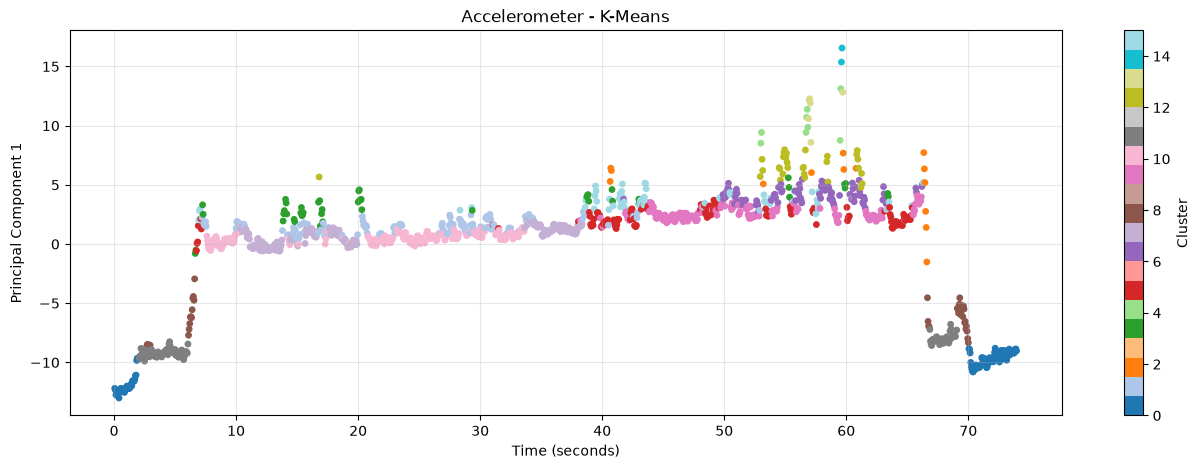

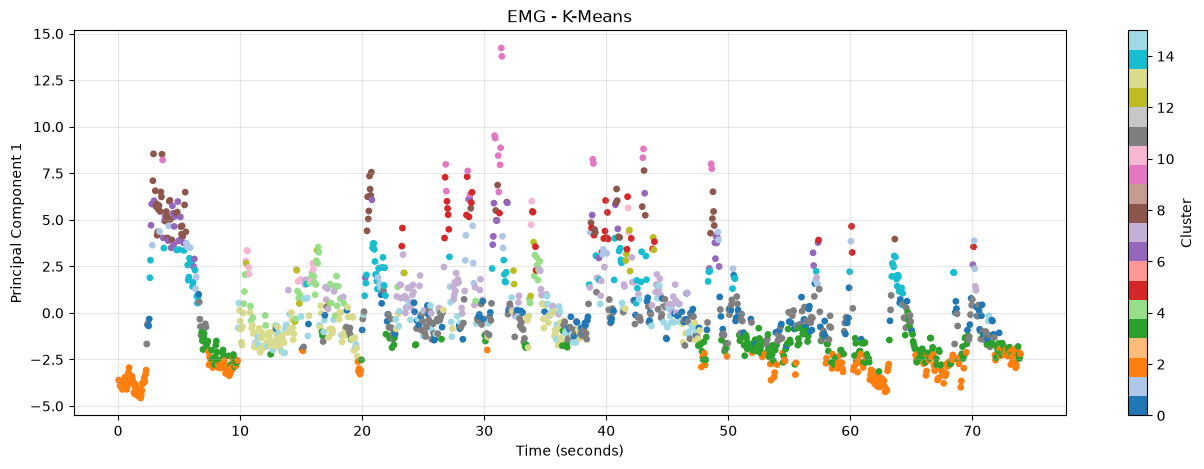

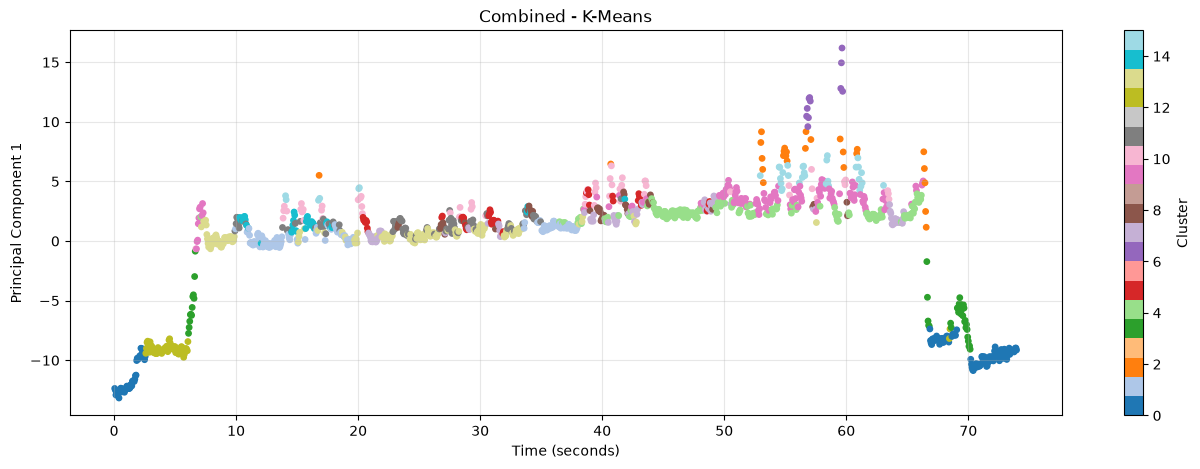

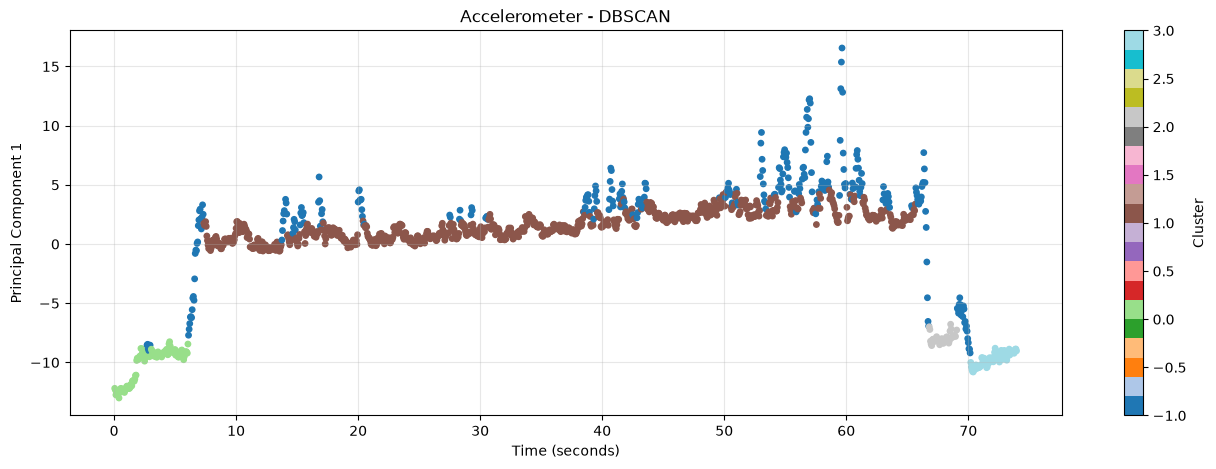

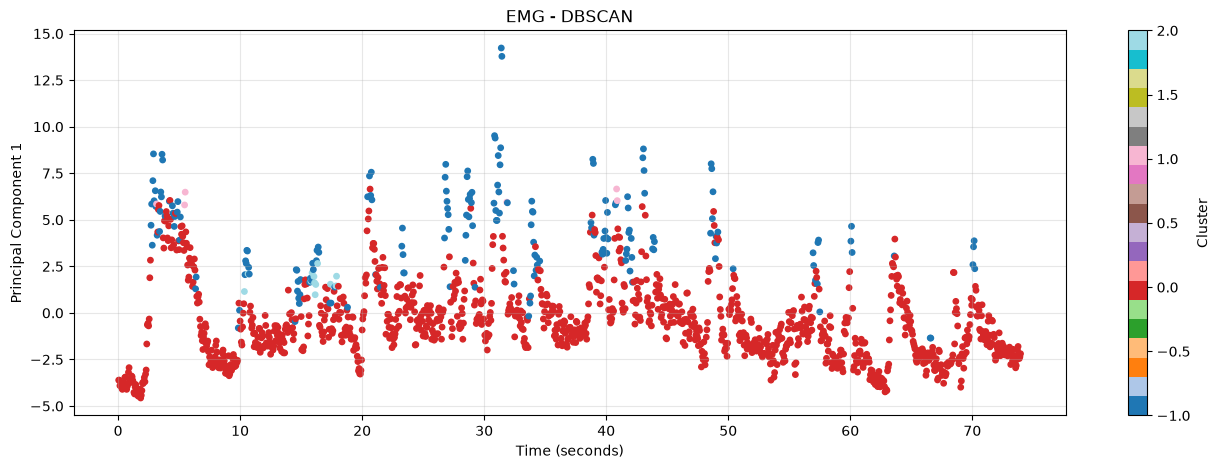

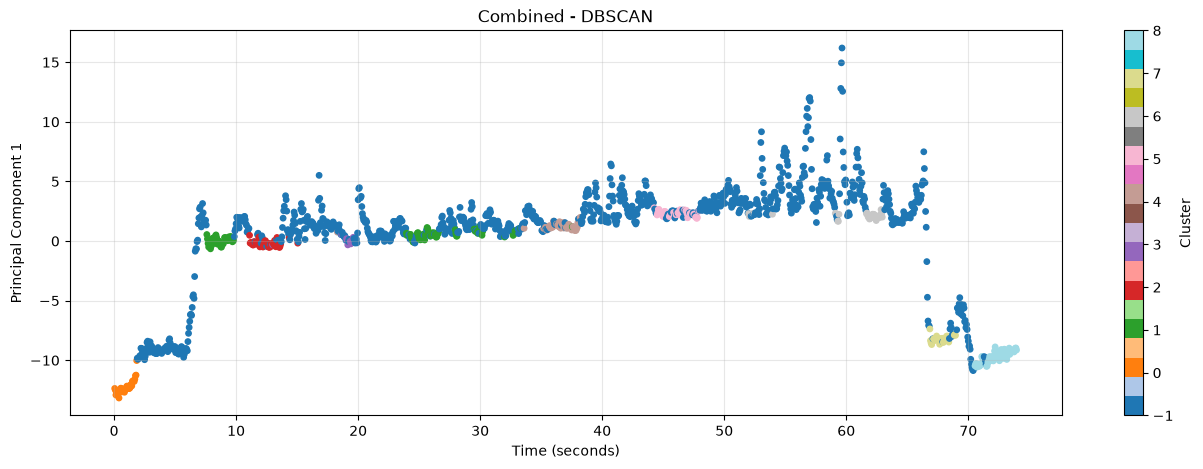

In [320]:


def plot_clusters_over_time(times, X_pca, labels, title):

    plt.figure(figsize=(16, 5))

    plt.scatter(
        times,
        X_pca[:, 0],
        c=labels,
        cmap="tab20",
        s=15
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Principal Component 1")
    plt.title(title)
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.3)
    plt.show()



plot_clusters_over_time(
    time_xyz,
    X_pca_xyz,
    clusters_xyz,
    "Accelerometer - K-Means"
)

plot_clusters_over_time(
    time_emg,
    X_pca_emg,
    clusters_emg,
    "EMG - K-Means"
)

plot_clusters_over_time(
    time_combined,
    X_pca_combined,
    clusters_combined,
    "Combined - K-Means"
)

plot_clusters_over_time(
    time_xyz,
    X_pca_xyz,
    dbscan_xyz,
    "Accelerometer - DBSCAN"
)

plot_clusters_over_time(
    time_emg,
    X_pca_emg,
    dbscan_emg,
    "EMG - DBSCAN"
)

plot_clusters_over_time(
    time_combined,
    X_pca_combined,
    dbscan_combined,
    "Combined - DBSCAN"
)


### Vergleich mit selbst gesetzten Intervallen

In [ ]:
def encode_labels(labels):
    # Movement names -> integer codes for the metrics
    return np.array([label_codes[label] for label in labels])

In [ ]:



datasets = {
    "Accelerometer": X_xyz_scaled,
    "EMG": X_emg_scaled,
    "Combined": X_combined_scaled
}
clustering_results = {
    "Accelerometer": {"K-Means": clusters_xyz, "DBSCAN": dbscan_xyz}
    ,"EMG": {"K-Means": clusters_emg, "DBSCAN": dbscan_emg}
    ,"Combined": {"K-Means": clusters_combined, "DBSCAN": dbscan_combined}}

label_datasets = {
    "Accelerometer": y_xyz,
    "EMG": y_emg,
    "Combined": y_combined
}

results = []

for name, algorithms in clustering_results.items():

    X = datasets[name]

    # Every window has a movement label (incl. rest)
    y_true = encode_labels(label_datasets[name])

    for algorithm, y_pred in algorithms.items():

        ari = adjusted_rand_score(y_true, y_pred)

        nmi = normalized_mutual_info_score(y_true, y_pred)

        # DBSCAN noise points (-1) excluded from silhouette
        if algorithm == "DBSCAN":
            mask = y_pred != -1
        else:
            mask = np.ones(len(y_pred), dtype=bool)

        unique_clusters = np.unique(y_pred[mask])

        if len(unique_clusters) >= 2 and mask.sum() > len(unique_clusters):
            silhouette = silhouette_score(
                X[mask],
                y_pred[mask]
            )
        else:
            silhouette = np.nan

        results.append({
            "Dataset": name,
            "Algorithm": algorithm,
            "Clusters": len(unique_clusters),
            "Noise points": np.sum(y_pred == -1),
            "ARI": ari,
            "NMI": nmi,
            "Silhouette": silhouette
        })

results_df = pd.DataFrame(results)

print(f"Echte Bewegungen inkl. Ruhe: {n_movements}")
print(results_df.round(3).to_string(index=False))

### Visualisierung der Heatmap von gelabelten Clustern mit berechneten

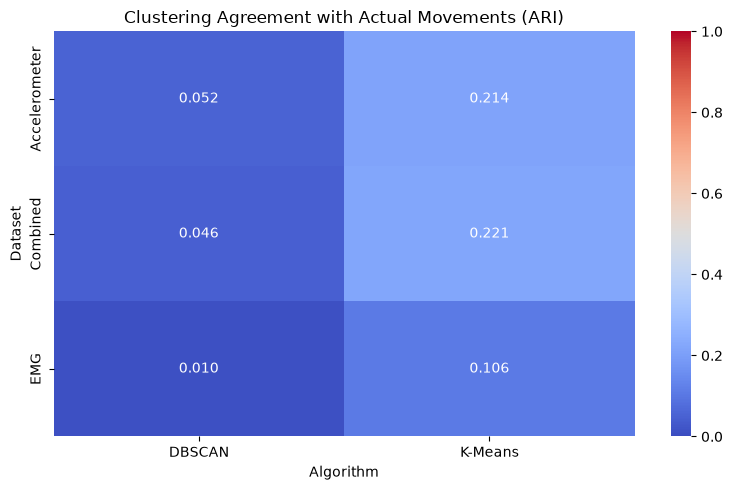

In [323]:
comparison = results_df.pivot(
    index="Dataset",
    columns="Algorithm",
    values="ARI"
)

plt.figure(figsize=(8, 5))

sns.heatmap(
    comparison,
    annot=True,
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    fmt=".3f"
)

plt.title("Clustering Agreement with Actual Movements (ARI)")
plt.tight_layout()
plt.show()

### Cluster Vergleich

In [ ]:
from sklearn.metrics.cluster import contingency_matrix


def plot_movement_comparison(true_labels, predicted_labels, title):

    matrix = contingency_matrix(
        encode_labels(true_labels),
        predicted_labels
    )

    plt.figure(figsize=(12, 7))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        yticklabels=sorted(set(true_labels), key=label_codes.get)
    )

    plt.xlabel("Discovered cluster")
    plt.ylabel("Actual movement")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_movement_comparison(
    y_combined,
    clusters_combined,
    "Combined - K-Means vs Actual Movements"
)

### Erkenntnis

Die eigentlichen Bewegungsabschnitte zu labeln ist zwar nett, bringt bei den Daten nur semi viel, aber die besten Daten für Clustering scheinen die kombinierten aus EMG und Acc zu sein, wobei Acc kanpp dahinter ist und EMG stark abfällt

Daher testen von anderen Paramtern für K-Means und Clustering

K-Means Testing

In [325]:
for k in range(2, 21):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_combined_scaled)

    score = silhouette_score(
        X_combined_scaled,
        labels
    )

    print(f"K={k}: Silhouette={score:.3f}")

K=2: Silhouette=0.449
K=3: Silhouette=0.460
K=4: Silhouette=0.282
K=5: Silhouette=0.267
K=6: Silhouette=0.260
K=7: Silhouette=0.222
K=8: Silhouette=0.222
K=9: Silhouette=0.213
K=10: Silhouette=0.207
K=11: Silhouette=0.181
K=12: Silhouette=0.176
K=13: Silhouette=0.187
K=14: Silhouette=0.155
K=15: Silhouette=0.178
K=16: Silhouette=0.174
K=17: Silhouette=0.158
K=18: Silhouette=0.157
K=19: Silhouette=0.166
K=20: Silhouette=0.165


DBSCAN Testing

In [ ]:

# Sensitivity check around the data-driven eps (Combined dataset)
EPS_FACTORS = [0.5, 0.75, 0.9, 1.0, 1.1, 1.25, 1.5, 2.0]

for factor in EPS_FACTORS:
    eps = dbscan_eps["Combined"] * factor
    model = DBSCAN(
        eps=eps,
        min_samples=DBSCAN_MIN_SAMPLES
    )

    labels = model.fit_predict(X_combined_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = sum(labels == -1)

    print(
        f"eps={eps:.3f} (x{factor}): "
        f"Clusters={n_clusters}, "
        f"Noise={noise}"
    )

### Erkenntnis:

8 scheinen die Beste Zuordnung bei den Daten zu sein

In [338]:


# Reduce data to 2 dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_combined_scaled)

# K-Means with 8 clusters
kmeans_8 = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)
# K-Means with 9 clusters
kmeans_9 = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)
clusters_8 = kmeans_8.fit_predict(X_combined_scaled)
clusters_9 = kmeans_9.fit_predict(X_combined_scaled)


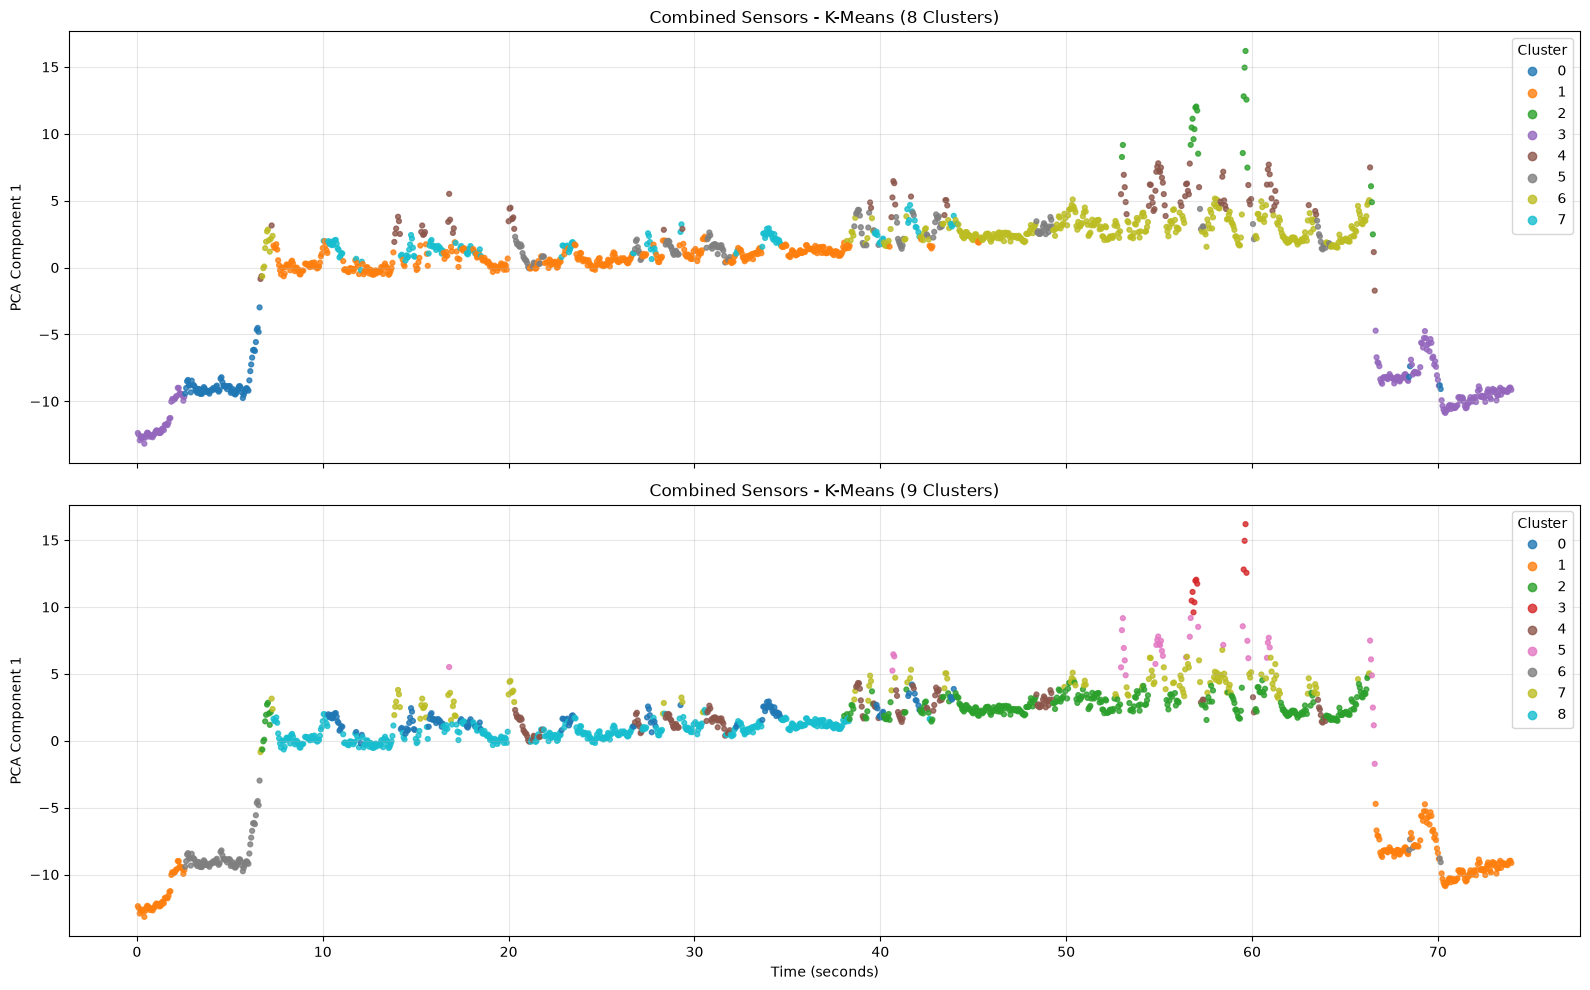

In [339]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

cluster_results = {
    "8 Clusters": clusters_8,
    "9 Clusters": clusters_9
}

for ax, (name, labels) in zip(axes, cluster_results.items()):

    scatter = ax.scatter(
        time_combined,
        X_pca[:, 0],
        c=labels,
        cmap="tab10",
        s=12,
        alpha=0.8
    )

    ax.set_title(f"Combined Sensors - K-Means ({name})")
    ax.set_ylabel("PCA Component 1")
    ax.grid(alpha=0.3)
    ax.legend(*scatter.legend_elements(), title="Cluster")

axes[-1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

## Samuel Teil Bericht

### CSV Konvertierung

Ein Python Skript wurde erstellt um c3d Dateien in ein CSV Format umzuwandeln.
Dadurch wurden die erste Testdatenreihe konviertiert für die weitere Verarbeitung.

### Inhalt der CSV

In der datei sidn folgende Daten vorhanden:

```csv
Time,Emg_1,Acc_1 :X,Acc_1 :Y,Acc_1 :Z,Emg_2,Acc_2 :X,Acc_2 :Y,Acc_2 :Z,Acc_3 :X,Acc_3 :Y,Acc_3 :Z,Emg_4,Acc_4 :X,Acc_4 :Y,Acc_4 :Z,Emg_5,Acc_5 :X,Acc_5 :Y,Acc_5 :Z,Emg_6,Acc_6 :X,Acc_6 :Y,Acc_6 :Z,Emg_7,Acc_7 :X,Acc_7 :Y,Acc_7 :Z,Acc_8 :X,Acc_8 :Y,Acc_8 :Z,Acc_9 :X,Acc_9 :Y,Acc_9 :Z,Acc_10 :X,Acc_10 :Y,Acc_10 :Z,Acc_11 :X,Acc_11 :Y,Acc_11 :Z,Acc_12 :X,Acc_12 :Y,Acc_12 :Z,Acc_13 :X,Acc_13 :Y,Acc_13 :Z,Acc_14 :X,Acc_14 :Y,Acc_14 :Z,Acc_15 :X,Acc_15 :Y,Acc_15 :Z,Acc_16 :X,Acc_16 :Y,Acc_16 :Z
```
Time ist ein abiträr hinzugefügtes Feature, das den zeitlichen Rahmen für jede Testwertzeile im halben millisekunden Takt klassifiziert.
Beim direkten untersuchen der Daten konnte festgestellt werden, dass
sehr viele spalten gar keine Werte beritstellen.
Grund: Es wurden nicht alle verfügbaren Sensoren des EMG Gerätes für diese Testreihe angwandt, aber natürlich als Werte (überall 0) mit aufgenommen.
Zu diesen zählen:

Emg_1, Emg_2, Emg_4, Acc_1 :X, Acc_1 :Y, Acc_1 :Z, Acc_2 :X, Acc_2 :Y, Acc_2 :Z, Acc_3 :X, Acc_3 :Y, Acc_3 :Z, Acc_4 :X, Acc_4 :Y, Acc_4 :Z, Acc_8 :X, Acc_8 :Y, Acc_8 :Z, Acc_9 :X, Acc_9 :Y, Acc_9 :Z, Acc_10 :X, Acc_10 :Y, Acc_10 :Z, Acc_11 :X, Acc_11 :Y, Acc_11 :Z, Acc_12 :X, Acc_12 :Y, Acc_12 :Z, Acc_13 :X, Acc_13 :Y, Acc_13 :Z, Acc_14 :X, Acc_14 :Y, Acc_14 :Z, Acc_15 :X, Acc_15 :Y, Acc_15 :Z, Acc_16 :X, Acc_16 :Y, Acc_16 :Z.

Die Daten mit tatsächlichen Werten(Die drei verwendeten Sensoren):
Acc_5 :X,	Acc_5 :Y,	Acc_5 :Z,	Acc_6 :X,	Acc_6 :Y,	Acc_6 :Z,	Acc_7 ,:X,	Acc_7 :Y,	Acc_7 :Z,	Emg_5,	Emg_6,	Emg_7,

Hierbei wurde ermittelt, dass EMG Spalten die eigentlichen EMG Daten sind und Acc_<Zahl> :XYZ die gemessene Beschleunigung des einzelnen Sensor in die jweilige Richtung ist

### Datenaufbereitung 

Um die Daten besser auswerten zu können, wurde ein jupyter Notebook verwendet.
In diesem wurden alle csv Daten erstaml importiert und alle und leeren spalten gelöscht. danach wurde Time als separte Spalte extrahiert sowie drei weitere Datensätze erstellt:
1. Nur die Beschleunigungsdaten
2. Nur die EMG Daten
3. Beide Datensätze kombiniert

Hiernach wurde  alle drei datensätze gegenbüber dem Zeitverlauf visualisiert. 
Aus den hervorgehenden Graphen wurden dann in die 15 Phasen, die für den ersten Testlauf als Richtlinie dienten, eingeteilt.

### Clustering

Um erstmal zu gucken, ob diese 15 Phasen tatsächlich, in den Daten geclustert werden können wurden die K-Means und DBSAN Algorithmen angewandt.
Das Ergebnis zeigte, dass es wenig Sinn machte, die Daten in bestimmte intervalle zu teilen. Die Intervall basierte aufteilung besaß nämlich eine sehr geringe Korrelation mit dem durchgeführten Clustering.

Dennoch gab es große Differenzen zwischen den datensätzen.
Während der 3. datensatz das beste Ergebnis lieferte und der 1. knapp dahinter waren, gab der alleinige EMg Datensatz ein sehr schlechtes Ergebnis bei beiden Cluster Algorithmen.
Erkenntnis: Alle Daten sind (vorerst) am besten für die weietere Analyse & später das Training geeignet.

Als letzter Schritt wurde gemessen wie viele Cluster in diesen Daten die sauberste und beste Aufteilung liefern. Dabei wurde mittels zwei verschieener Verfahren für DBSACN und auch K-Maens festgestellt, dass zwischen 7-9 Cluster die beste Datenaufteilung liefern

### Fazit

Auf Basis der durchgeführten Datenanalyse können vertiefende Analyen durchgeführt werden und weitere Testreihen untersucht werden, um die ersten Modelle zu erstellen.


